In [1]:
import uproot, os, sys
import numpy as np
import matplotlib.pyplot as plt

sys.path.append('..')
from globalsC2 import *
from v2Helpers import *
import PDEStyle as PS

ms = PS.MyStyleSet()
ms.SetMPLcolors()
plt.rcParams.update({
    'font.size': 14, 'axes.titlesize': 15, 'axes.labelsize': 14,
    'xtick.labelsize': 13, 'ytick.labelsize': 13, 'legend.fontsize': 11,
})

CF4HOME: /Users/austindestcroix/Desktop/school_holders/projects/sbc/CF4
COMP2PATH: /Users/austindestcroix/Desktop/school_holders/projects/sbc/CF4/comp2


In [2]:
## --- CONFIG ---

BATCH_PATH = '/Users/austindestcroix/Desktop/school_holders/projects/sbc/g4cf4_newOptics/2batchOutput/ref_photonBomb_MS/'

REF_MAP = {           # folder name -> reflectivity %
    'ref0':   0,
    'ref05p': 5,
    'ref10p': 10,
}
HEIGHT_TAG = {        # filename substring -> source height (cm)
    '1d5cm': 1.5,
    '3cm':   3.0,
    '5cm':   5.0,
}

HIST_LOWER = 100        # lower edge of NPE histogram
HIST_UPPER = 6000      # upper edge of NPE histogram  <-- change this

HIST_CFG = {          # per height: nbins only (range uses HIST_LOWER/UPPER above)
    1.5: {'nbins': 40},
    3.0: {'nbins': 80},
    5.0: {'nbins': 150},
}
# REF_COLORS    = {0: 'C0', 5: 'C1', 10: 'C2'}  # color per reflectivity
REF_COLORS    = {0: ms.air.col, 5: ms.cf4.col, 10: ms.red.col}  # color per reflectivity
FIT_HALF_BINS = 3                              # +/- N bins around peak for Gaussian fit

In [3]:
from types import SimpleNamespace

sims = {}  # keyed by (folder, height)

for folder, ref_pct in REF_MAP.items():
    path = os.path.join(BATCH_PATH, folder)
    for fname in sorted(os.listdir(path)):
        if not fname.endswith('.root'):
            continue
        height = next((h for tag, h in HEIGHT_TAG.items() if tag in fname), None)
        if height is None:
            print(f'Warning: unknown height for {fname}'); continue
        npe = uproot.open(os.path.join(path, fname))['simOutput']['fTouchPE'].array(library='np')
        sims[(folder, height)] = SimpleNamespace(
            folder=folder, ref_pct=ref_pct, height=height, npe=npe,
            bin_counts=None, bin_edges=None, bin_centers=None, fit=None
        )

HEIGHTS = sorted({h for (_, h) in sims})
print(f'Loaded {len(sims)} sims | reflectivities: {list(REF_MAP.values())}% | heights: {HEIGHTS} cm')

Loaded 9 sims | reflectivities: [0, 5, 10]% | heights: [1.5, 3.0, 5.0] cm


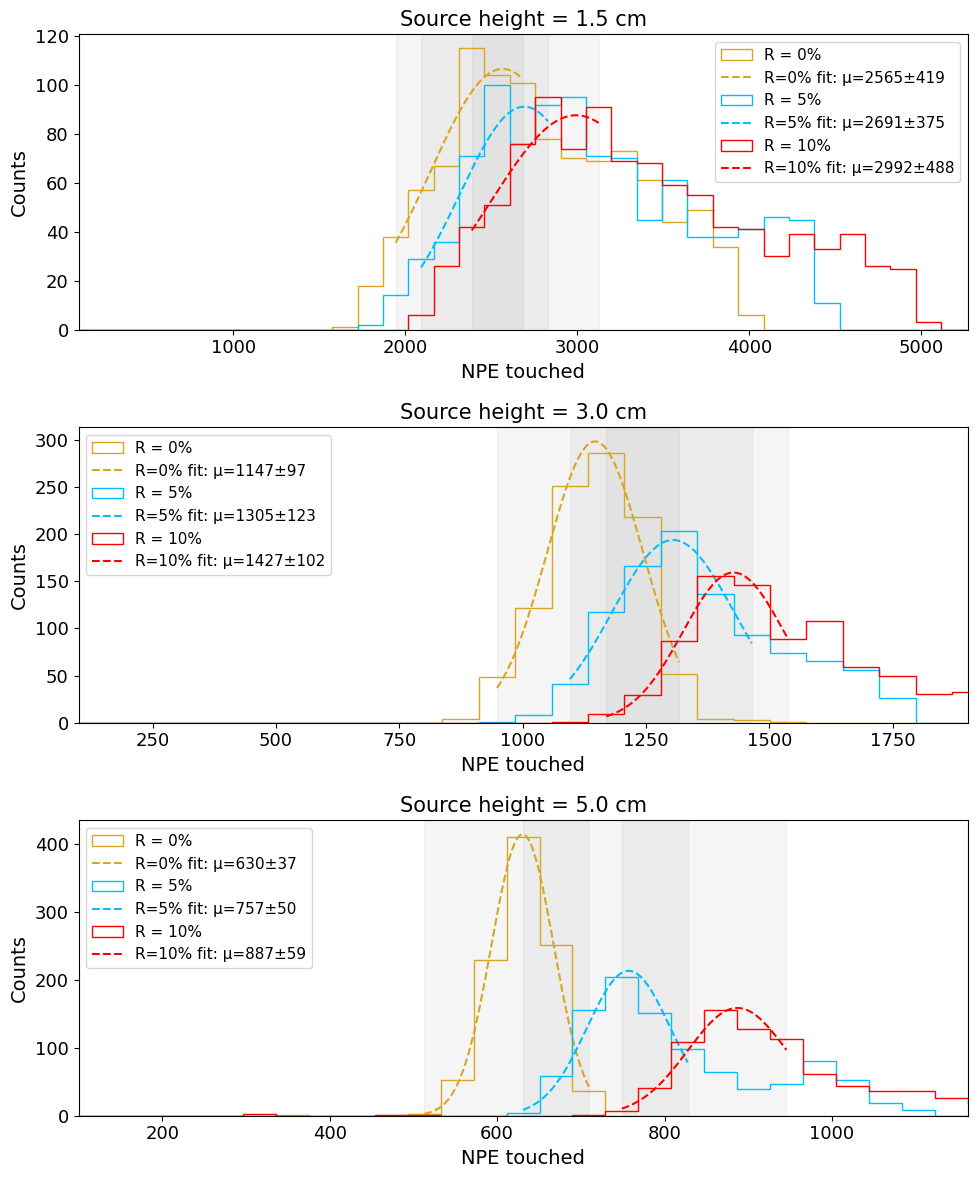

In [4]:
# One subplot per source height; all reflectivities overlaid on each
fig, axes = plt.subplots(len(HEIGHTS), 1, figsize=(10, 4 * len(HEIGHTS)), sharex=False)
height_ax = dict(zip(HEIGHTS, axes))

for (folder, height), sim in sorted(sims.items()):
    ax  = height_ax[height]
    cfg = HIST_CFG[height]
    counts, edges, _ = ax.hist(sim.npe, bins=cfg['nbins'], range=(HIST_LOWER, HIST_UPPER),
                                histtype='step', color=REF_COLORS[sim.ref_pct],
                                label=f'R = {sim.ref_pct}%')
    sim.bin_counts, sim.bin_edges = counts, edges
    sim.bin_centers = 0.5 * (edges[1:] + edges[:-1])

    # Gaussian fit around histogram peak
    ip     = np.argmax(counts)
    lo, hi = max(0, ip - FIT_HALF_BINS), min(len(counts), ip + FIT_HALF_BINS)
    sim.fit = fit_histogram_gaussian(sim.bin_centers[lo:hi], counts[lo:hi])
    mu, sig = sim.fit.values['mean'], sim.fit.values['sigma']

    x_fit = np.linspace(sim.bin_centers[lo], sim.bin_centers[hi - 1], 200)
    ax.plot(x_fit, gaussian(x_fit, sim.fit.values['amplitude'], mu, sig),
            color=REF_COLORS[sim.ref_pct], lw=1.5, ls='--',
            label=f'R={sim.ref_pct}% fit: μ={mu:.0f}±{sig:.0f}')
    ax.axvspan(sim.bin_centers[lo], sim.bin_centers[hi - 1], alpha=0.08, color='gray')

for h, ax in height_ax.items():
    ax.set_title(f'Source height = {h} cm')
    ax.set_xlabel('NPE touched'); ax.set_ylabel('Counts')
    ax.legend()
    
    # set xlim dynamically from max bin entry across all reflectivities for this height
    max_count = max(sims[(folder, h)].bin_counts.max() for folder in REF_MAP)
    ax.set_xlim(
        HIST_LOWER, min(HIST_UPPER, sims[(folder, h)].bin_centers[np.argmax(sims[(folder, h)].bin_counts)] + 5 * sims[(folder, h)].fit.values['sigma'])
    )

plt.tight_layout(); plt.show()

[1.5, 3.0, 5.0]
[0.9532746410731295, 0.8788848158833853, 0.8326009396607702]
R=0%: average frac = 0.888
[1.0, 1.0, 1.0]
R=5%: average frac = 1.000
[1.1119351774613273, 1.093789299413607, 1.171467390373704]
R=10%: average frac = 1.126


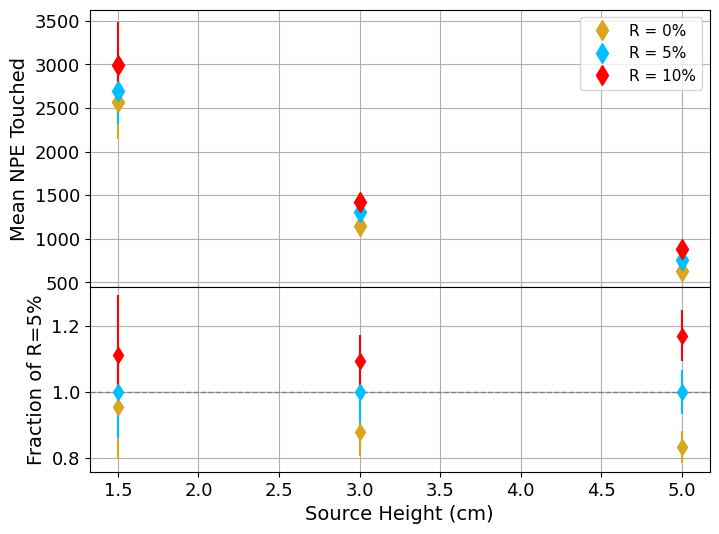

In [5]:
# Summary: Gaussian peak (mean +/- sigma) vs source height, by reflectivity
REF_NORM = 5   # reflectivity % to normalize against in residual panel

fig, (ax_top, ax_bot) = plt.subplots(2, 1, figsize=(8, 6), sharex=True,
                                      gridspec_kw={'height_ratios': [3, 2]})

ref_norm_folder = next(f for f, r in REF_MAP.items() if r == REF_NORM)
norm_means = [sims[(ref_norm_folder, h)].fit.values['mean'] for h in HEIGHTS]

print(HEIGHTS)
for folder, ref_pct in REF_MAP.items():
    row    = [sims[(folder, h)] for h in HEIGHTS]
    means  = [s.fit.values['mean']  for s in row]
    sigmas = [s.fit.values['sigma'] for s in row]

    ax_top.errorbar(HEIGHTS, means, yerr=sigmas, marker='d', markersize=10,
                    linestyle='None', color=REF_COLORS[ref_pct], label=f'R = {ref_pct}%')

    frac       = [m / n for m, n in zip(means, norm_means)]
    frac_err   = [s / n for s, n in zip(sigmas, norm_means)]
    ax_bot.errorbar(HEIGHTS, frac, yerr=frac_err, marker='d', markersize=8,
                    linestyle='None', color=REF_COLORS[ref_pct], label=f'R = {ref_pct}%')
    print(frac)
    print(f"R={ref_pct}%: average frac = {np.mean(frac):0.3f}")

ax_top.set_ylabel('Mean NPE Touched')
# ax_top.set_title('Peak NPE vs Source Height by Reflectivity')
ax_top.legend()

ax_bot.axhline(1.0, color='gray', lw=1, ls='--')
ax_bot.set_xlabel('Source Height (cm)')
ax_bot.set_ylabel(f'Fraction of R={REF_NORM}%')

# plt.tight_layout();

ax_top.grid()
ax_bot.grid()

plt.subplots_adjust(hspace=0.0) 
plt.show()

In [6]:
## first arg increases LY, second arg decreases LY
sysOptics = [0.11, 0.13] ## increase LY by this much

heightError = [0.18, 0.36] ## from photon bomb
heightError = [0, 0]

sysNCA = [0, 0.22-0.17] ## make LY lower by this fraction (if actually 0.22 we dont correct enough)

lyvis = [2.88, 2.93, 2.39]

increaseError_stat = np.abs(lyvis[0] - lyvis[1])
reduceError_stat = np.abs(lyvis[2] - lyvis[0])

print(f"ly vis stat errors = {lyvis[0]} +{increaseError_stat:0.3f} -{reduceError_stat:0.3f} ph/keV")

fullSysErrorUp = lyvis[0] * np.sqrt(sysOptics[0]**2 + sysNCA[0]**2 + heightError[0]**2)
fullSysErrorDown = lyvis[0] * np.sqrt(sysOptics[1]**2 + sysNCA[1]**2 + heightError[1]**2)

print("ly vis sys errors = +{0:0.3f} -{1:0.3f}".format(fullSysErrorUp, fullSysErrorDown) + " ph/keV")

fullPosError = lyvis[0] * np.sqrt((increaseError_stat/lyvis[0])**2 + (fullSysErrorUp/lyvis[0])**2)
fullReduceError = lyvis[0] * np.sqrt((reduceError_stat/lyvis[0])**2 + (fullSysErrorDown/lyvis[0])**2)

print(f"full plus error = {fullPosError:0.3f} ph/keV")
print(f"full reduce error = {fullReduceError:0.3f} ph/keV")

ly vis stat errors = 2.88 +0.050 -0.490 ph/keV
ly vis sys errors = +0.317 -0.401 ph/keV
full plus error = 0.321 ph/keV
full reduce error = 0.633 ph/keV


In [7]:
lyAll = [4.07, 4.26, 3.91]
increaseError_all = np.abs(lyAll[0] - lyAll[1])
reduceError_all = np.abs(lyAll[2] - lyAll[0])
print(f"LY all stat errors: {lyAll[0]} +{increaseError_all:0.3f} -{reduceError_all:0.3f}")

lyAll_sysErrorUp = lyAll[0] * np.sqrt(sysOptics[0]**2 + sysNCA[0]**2 + heightError[0]**2)
lyAll_sysErrorDown = lyAll[0] * np.sqrt(sysOptics[1]**2 + sysNCA[1]**2 + heightError[1]**2)
print(f"LY all sys errors: +{lyAll_sysErrorUp:0.3f} -{lyAll_sysErrorDown:0.3f} ph/keV")
lyAll_totalUpError = lyAll[0] * np.sqrt((increaseError_all/lyAll[0])**2 + (lyAll_sysErrorUp/lyAll[0])**2)
lyAll_totalDownError = lyAll[0] * np.sqrt((reduceError_all/lyAll[0])**2 + (lyAll_sysErrorDown/lyAll[0])**2)
print(f"LY all total errors: +{lyAll_totalUpError:0.3f} -{lyAll_totalDownError:0.3f} ph/keV")

lyUV = lyAll[0] - lyvis[0]
upperStat_UV = np.sqrt(increaseError_stat**2 + increaseError_all**2)
lowerStat_UV = np.sqrt(reduceError_stat**2 + reduceError_all**2)

print(f"\n\nLY UV stat errors: {lyUV:0.3f} +{upperStat_UV:0.3f} -{lowerStat_UV:0.3f} ph/keV")


lyUV_sysUp = lyUV * np.sqrt(sysOptics[0]**2 + sysNCA[0]**2 + heightError[0]**2)
lyUV_sysDown = lyUV * np.sqrt(sysOptics[1]**2 + sysNCA[1]**2 + heightError[1]**2)

print(f"LY UV sys errors: +{lyUV_sysUp:0.3f} -{lyUV_sysDown:0.3f} ph/keV")

fullPosError_UV = lyUV * np.sqrt((upperStat_UV/lyUV)**2 + (lyUV_sysUp/lyUV)**2)
fullReduceError_UV = lyUV * np.sqrt((lowerStat_UV/lyUV)**2 + (lyUV_sysDown/lyUV)**2)

print(f"full UV result = {lyUV:0.3f} +{fullPosError_UV:0.3f} -{fullReduceError_UV:0.3f} ph/keV")

LY all stat errors: 4.07 +0.190 -0.160
LY all sys errors: +0.448 -0.567 ph/keV
LY all total errors: +0.486 -0.589 ph/keV


LY UV stat errors: 1.190 +0.196 -0.515 ph/keV
LY UV sys errors: +0.131 -0.166 ph/keV
full UV result = 1.190 +0.236 -0.541 ph/keV


In [8]:
visibleFraction = lyvis[0] / lyAll[0]
visFracUpError = visibleFraction * np.sqrt((fullPosError/lyvis[0])**2 + (lyAll_totalUpError/lyAll[0])**2)
visFracDownError = visibleFraction * np.sqrt((fullReduceError/lyvis[0])**2 + (lyAll_totalDownError/lyAll[0])**2)
print(f"\n\nVis fraction = {visibleFraction:0.3f} +{visFracUpError:0.3f} -{visFracDownError:0.3f}")



Vis fraction = 0.708 +0.116 -0.186


In [9]:
def calckb(lyGamma, lyAlpha, density, dedx):
  #dEdx in MeV cm
  realdEdx = dedx * density
  return (lyGamma/lyAlpha - 1)/realdEdx

calckb(4, 0.1, 1.6, 1000)

0.024375

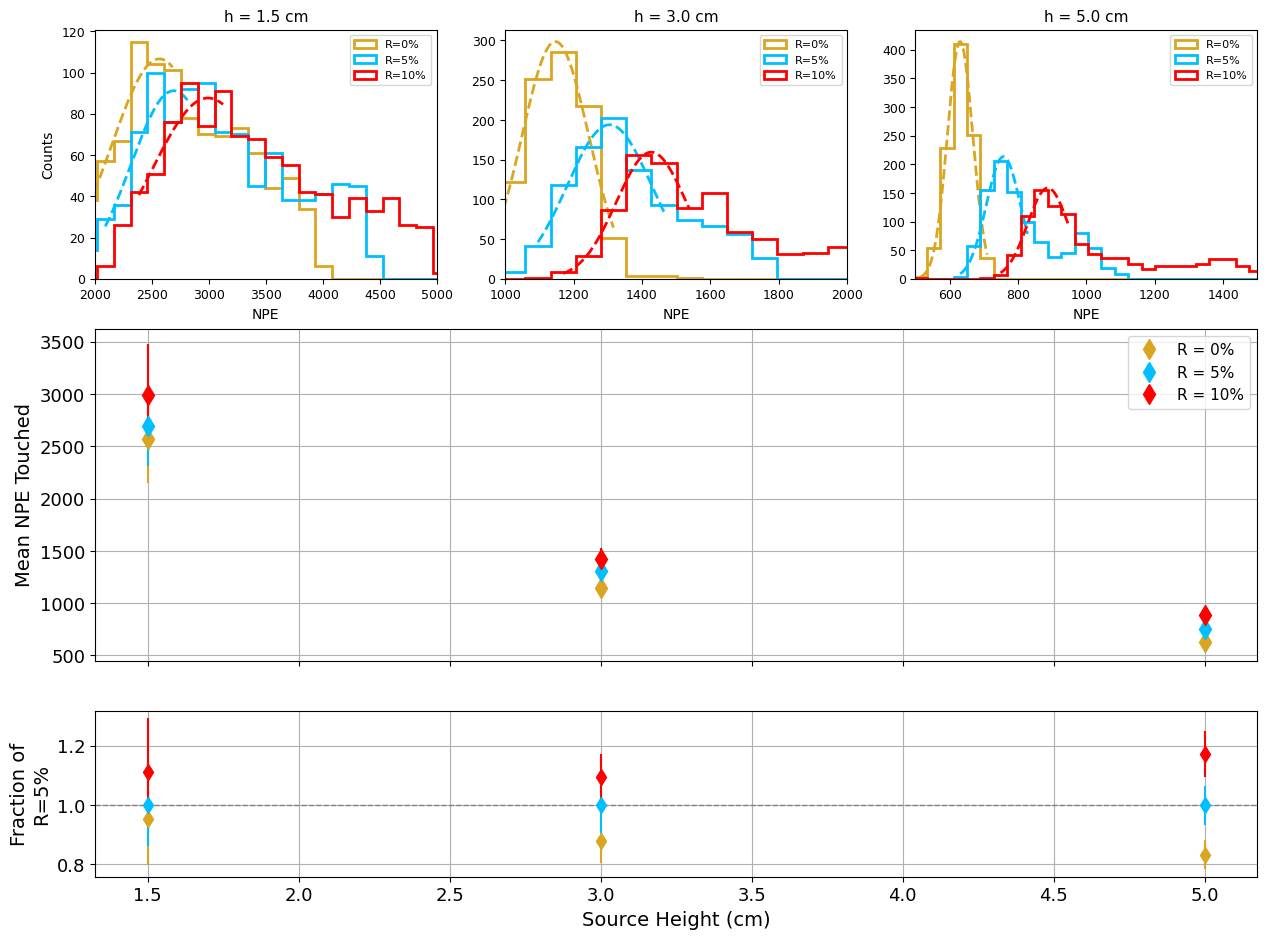

In [11]:
import matplotlib.gridspec as gridspec

ncols = len(HEIGHTS)
fig   = plt.figure(figsize=(5 * ncols, 11))
gs    = gridspec.GridSpec(3, ncols, figure=fig,
                          height_ratios=[1.5, 2, 1],
                          hspace=0.2, wspace=0.2)

hist_axes = [fig.add_subplot(gs[0, i]) for i in range(ncols)]
ax_sum    = fig.add_subplot(gs[1, :])
ax_res    = fig.add_subplot(gs[2, :], sharex=ax_sum)

# --- top row: one histogram per height, all reflectivities overlaid ---
for (folder, height), sim in sorted(sims.items()):
    ax  = hist_axes[HEIGHTS.index(height)]
    cfg = HIST_CFG[height]
    ax.hist(sim.npe, bins=cfg['nbins'], range=(HIST_LOWER, HIST_UPPER),
            histtype='step', color=REF_COLORS[sim.ref_pct], label=f'R={sim.ref_pct}%', lw=2)
    if sim.fit is not None:
        mu, sig = sim.fit.values['mean'], sim.fit.values['sigma']
        ip = np.argmax(sim.bin_counts)
        lo = max(0, ip - FIT_HALF_BINS)
        hi = min(len(sim.bin_counts), ip + FIT_HALF_BINS)
        x_fit = np.linspace(sim.bin_centers[lo], sim.bin_centers[hi - 1], 200)
        ax.plot(x_fit, gaussian(x_fit, sim.fit.values['amplitude'], mu, sig),
                color=REF_COLORS[sim.ref_pct], lw=2, ls='--')


for i, (h, ax) in enumerate(zip(HEIGHTS, hist_axes)):
    # xlim: span of populated bins across all reflectivities at this height + 10% padding
    # all_centers = np.concatenate([s.bin_centers for (f, ht), s in sims.items() if ht == h])
    # all_counts  = np.concatenate([s.bin_counts  for (f, ht), s in sims.items() if ht == h])
    # populated   = all_centers[all_counts > 0]
    # if len(populated) > 0:
    #     pad = 0.1 * (populated.max() - populated.min())
    #     ax.set_xlim(populated.min() - pad, populated.max() + pad)

    ax.set_title(f'h = {h} cm', fontsize=11)
    ax.set_xlabel('NPE', fontsize=10)
    if i == 0:
        ax.set_ylabel('Counts', fontsize=10)
    ax.legend(fontsize=8)
    ax.tick_params(labelsize=9)

# --- middle: mean NPE vs height ---
ref_norm_folder = next(f for f, r in REF_MAP.items() if r == REF_NORM)
norm_means = [sims[(ref_norm_folder, h)].fit.values['mean'] for h in HEIGHTS]

for folder, ref_pct in REF_MAP.items():
    row    = [sims[(folder, h)] for h in HEIGHTS]
    means  = [s.fit.values['mean']  for s in row]
    sigmas = [s.fit.values['sigma'] for s in row]
    ax_sum.errorbar(HEIGHTS, means, yerr=sigmas, marker='d', markersize=10,
                    linestyle='None', color=REF_COLORS[ref_pct], label=f'R = {ref_pct}%')

ax_sum.set_ylabel('Mean NPE Touched')
ax_sum.legend()
ax_sum.grid()
ax_sum.tick_params(labelbottom=False)

# --- bottom: fraction vs REF_NORM ---
for folder, ref_pct in REF_MAP.items():
    row      = [sims[(folder, h)] for h in HEIGHTS]
    means    = [s.fit.values['mean']  for s in row]
    sigmas   = [s.fit.values['sigma'] for s in row]
    frac     = [m / n for m, n in zip(means, norm_means)]
    frac_err = [s / n for s, n in zip(sigmas, norm_means)]
    ax_res.errorbar(HEIGHTS, frac, yerr=frac_err, marker='d', markersize=8,
                    linestyle='None', color=REF_COLORS[ref_pct], label=f'R = {ref_pct}%')

ax_res.axhline(1.0, color='gray', lw=1, ls='--')
ax_res.set_xlabel('Source Height (cm)')
ax_res.set_ylabel(f'Fraction of\nR={REF_NORM}%', fontsize=14)
ax_res.grid()

hist_axes[0].set_xlim(2000, 5000)
hist_axes[1].set_xlim(1000, 2000)
hist_axes[2].set_xlim(500, 1500)


plt.show()

In [10]:
def propagate_kb_errors(lyGamma, lyGamma_up, lyGamma_down, lyAlpha, lyAlpha_err, density, dedx):
    """
    Numerical error propagation for calckb via central-difference partial derivatives.

    Parameters
    ----------
    lyGamma, lyAlpha     : central values
    lyGamma_up/down      : asymmetric +/- uncertainties on lyGamma
    lyAlpha_err          : symmetric uncertainty on lyAlpha
    density              : g/cm^3
    dedx                 : mass stopping power (MeV cm^2/g)

    Returns
    -------
    kb, kb_err_up, kb_err_down
    """
    eps_g = lyGamma * 1e-5   # step ~ 0.001% of value
    eps_a = lyAlpha * 1e-5

    kb0 = calckb(lyGamma, lyAlpha, density, dedx)

    # partial derivatives
    dkb_dlg = (calckb(lyGamma + eps_g, lyAlpha, density, dedx) -
               calckb(lyGamma - eps_g, lyAlpha, density, dedx)) / (2 * eps_g)
    dkb_dla = (calckb(lyGamma, lyAlpha + eps_a, density, dedx) -
               calckb(lyGamma, lyAlpha - eps_a, density, dedx)) / (2 * eps_a)

    print(f"  dkb/dLg = {dkb_dlg:.4e}   dkb/dLa = {dkb_dla:.4e}")

    contrib_la = abs(dkb_dla) * lyAlpha_err          # symmetric — same for up and down

    kb_err_up   = np.sqrt((dkb_dlg * lyGamma_up)  **2 + contrib_la**2)
    kb_err_down = np.sqrt((dkb_dlg * lyGamma_down)**2 + contrib_la**2)

    return kb0, kb_err_up, kb_err_down


# --- example call ---
density = 1.6      # g/cm^3  (liquid CF4)
dedx    = 1000.0   # MeV cm^2/g  (edit as needed)

lyA     = 0.1      # lyAlpha central value
lyA_err = 0.031     # fixed uncertainty on lyAlpha

lyG      = lyAll[0]    # central lyGamma from cell above
lyG_up   = lyAll_totalUpError   # + stat uncertainty
lyG_down = lyAll_totalDownError    # - stat uncertainty

kb, kb_up, kb_down = propagate_kb_errors(lyG, lyG_up, lyG_down, lyA, lyA_err, density, dedx)
print(f"\nkb = {kb:.4f}  +{kb_up:.4f}  -{kb_down:.4f}  (cm/MeV)")

  dkb/dLg = 6.2500e-03   dkb/dLa = -2.5438e-01

kb = 0.0248  +0.0085  -0.0087  (cm/MeV)
